# Explicabilidade das LSTMs: SHAP, LIME e pacotes de evidência (E6)

Este notebook apresenta os resultados da etapa E6 nos dois sistemas do OpenRCA (Telecom e Bank):

1. **localização via XAI (RQ2):** as atribuições de SHAP e LIME, agregadas por componente, apontam o componente da falha? Comparação pareada com o ranqueamento nativo da LSTM (E5) e com as heurísticas de z-score (E4);
2. **sensibilidade** à isenção dos KPIs de disponibilidade (ameaça nº 1);
3. **fidelidade** (deleção e inserção), **estabilidade** (entre seeds e entre janelas vizinhas) e **concordância** (SHAP × LIME, IG × SHAP);
4. **categoria de motivo** sugerida pelas atribuições, contra a frequência de treino;
5. um **pacote de evidência** de exemplo, do valor bruto da telemetria até o mapa de atribuições, como o agente da E7 vai recebê-lo.

**Fontes.** As tabelas vêm de `reports/tables/xai_<sistema>_<nome>.json`, geradas por `tcc-rca xai` (configs `xai.yaml` e `xai_sem_isencao.yaml`). Os valores por janela vêm dos artefatos de cada execução (`xai_ranks.csv`, `xai_categories.csv`, `xai_quality.csv`). As decisões estão no ADR 0016; as ameaças, em `docs/AMEACAS_VALIDADE.md` (itens 11 a 14).

**Como ler.** As medições usam **janelas-oráculo**, que terminam 5 min após o início de cada falha testada (como na E4 e na E5); se a falha começa nos primeiros minutos do dia, usa-se a primeira janela completa do dia (ADR 0019). Desde o ADR 0019, a pontuação explicada da previsora lê só os **últimos 6 minutos** da janela. Os pacotes de evidência usam a janela de maior pontuação do detector dentro de cada consulta, sem olhar o rótulo. Os intervalos são de 95%, por bootstrap sobre falhas. "Superior" e "inferior" vêm da diferença **pareada** nas mesmas falhas, nunca da sobreposição de intervalos.

In [1]:
import json
import os
from collections import Counter
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

from tcc_rca.config import load_config
from tcc_rca.ingestion.cases import read_failures
from tcc_rca.ingestion.timeutil import parse_local, utc_to_local_str

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)  # the project's configs use paths relative to the repository root
torch.set_num_threads(1)

TABLES = Path("reports/tables")
SYSTEMS = ["Telecom", "Bank"]
SYSTEM_CONFIGS = {
    "Telecom": ["configs/base.yaml"],
    "Bank": ["configs/base.yaml", "configs/system/bank.yaml"],
}
RUNS = ("xai", "xai_sem_isencao")


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


T = {(s, n): read_json(TABLES / f"xai_{s}_{n}.json") for s in SYSTEMS for n in RUNS}
ART = {k: Path("experiments") / v["run_dir"] / "artifacts" for k, v in T.items()}
display(
    pl.DataFrame(
        [
            {
                "sistema": s,
                "execução": n,
                "run_dir": T[(s, n)]["run_dir"],
                "LSTMs explicadas (E5)": T[(s, n)]["explained_lstm_run"],
                "segundos": T[(s, n)]["seconds"],
            }
            for s, n in T
        ]
    )
)

sistema,execução,run_dir,LSTMs explicadas (E5),segundos
str,str,str,str,f64
"""Telecom""","""xai""","""20261117T025449-xai""","""20261117T022802-lstm""",74.4
"""Telecom""","""xai_sem_isencao""","""20261117T025607-xai_sem_isenca…","""20261117T024942-lstm_sem_isenc…",72.3
"""Bank""","""xai""","""20261117T051545-xai""","""20261117T041757-lstm""",173.6
"""Bank""","""xai_sem_isencao""","""20261117T051842-xai_sem_isenca…","""20261117T050609-lstm_sem_isenc…",171.5


### Estilo dos gráficos

Mesma paleta do notebook da E1–E4, validada para daltonismo. Cada combinação modelo/explicador tem sempre a mesma cor:

- **azul:** previsora + SHAP;
- **laranja:** previsora + LIME;
- **verde-água:** classificadora + SHAP;
- **amarelo:** classificadora + LIME.

As referências (heurísticas, ordem aleatória, prior) ficam em cinza. Verde-água e amarelo têm menos de 3:1 de contraste com o fundo, por isso todo gráfico traz rótulos diretos ou uma tabela ao lado. Para atribuições com sinal, a escala é divergente: azul (empurra a pontuação para baixo), cinza (nada) e vermelho (empurra para cima).

In [2]:
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # blue, orange, aqua, yellow
MUTED, INK, INK2, GRID, AXIS = "#898781", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
SURFACE = "#fcfcfb"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.frameon": False,
        "legend.fontsize": 8,
        "lines.linewidth": 2,
        "font.family": "sans-serif",
        "figure.dpi": 110,
    }
)

COMBOS = {  # key in the tables -> (label, color)
    "lstm_forecast/shap": ("previsora · SHAP", SLOTS[0]),
    "lstm_forecast/lime": ("previsora · LIME", SLOTS[1]),
    "lstm_classifier/shap": ("classificadora · SHAP", SLOTS[2]),
    "lstm_classifier/lime": ("classificadora · LIME", SLOTS[3]),
}
MODEL_LABEL = {"lstm_forecast": "previsora", "lstm_classifier": "classificadora"}
MODEL_COLOR = {"lstm_forecast": SLOTS[0], "lstm_classifier": SLOTS[2]}


def ci_text(e, digits=2):
    return f"{e['value']:.{digits}f} [{e['ci_low']:.{digits}f}, {e['ci_high']:.{digits}f}]"


def diff_text(p):
    return f"{p['value']:+.3f} [{p['ci_low']:+.3f}, {p['ci_high']:+.3f}]"


def clean_y(ax, labels):
    ax.set_yticks(range(len(labels)), labels)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)

## 1. O que foi explicado e como

As duas LSTMs da E5 foram explicadas na seed 0; as seeds 1–4 entram só na medição de estabilidade.

- **Previsora:** a pontuação de anomalia (erro de previsão normalizado; média dos 10 maiores por minuto; máximo dos **últimos 6 minutos**, ADR 0019), reimplementada em PyTorch e testada como idêntica à da E5.
- **Classificadora:** a probabilidade de "falha iniciada nos últimos 5 min".

Os parâmetros abaixo foram fixados em `configs/base.yaml` antes de medir.

In [3]:
cfg_x = load_config("configs/base.yaml", "configs/experiment/xai.yaml").explain
params = [
    (
        "SHAP",
        "GradientExplainer (expected gradients)",
        f"fundo: {cfg_x.background_windows} janelas normais; {cfg_x.shap_samples} amostras",
    ),
    (
        "LIME",
        "uma variável binária por série componente::kpi",
        f"off = mediana normal; {cfg_x.lime_samples} amostras; kernel {cfg_x.lime_kernel_width}",
    ),
    (
        "IG (captum)",
        "verificação cruzada do SHAP",
        f"{cfg_x.ig_steps} passos; {cfg_x.ig_windows_per_fold} janelas por dobra",
    ),
    ("Componente", "soma das importâncias positivas dos KPIs", "variante: média das 3 maiores"),
    (
        "Fidelidade",
        "deleção / inserção dos k mais importantes",
        f"k ∈ {list(cfg_x.deletion_steps)}; {cfg_x.random_orders} ordens aleatórias",
    ),
    (
        "Estabilidade",
        f"Jaccard e Kendall dos top-{cfg_x.top_k}",
        f"seed 0 vs. seeds {list(cfg_x.stability_seeds)}; janelas ±1 min",
    ),
    (
        "Pacotes",
        f"janela: {cfg_x.evidence_detector}",
        f"atribuições citáveis: {cfg_x.evidence_explained}",
    ),
]
display(pl.DataFrame(params, schema=["item", "método", "parâmetros"], orient="row"))

item,método,parâmetros
str,str,str
"""SHAP""","""GradientExplainer (expected gr…","""fundo: 100 janelas normais; 20…"
"""LIME""","""uma variável binária por série…","""off = mediana normal; 3000 amo…"
"""IG (captum)""","""verificação cruzada do SHAP""","""32 passos; 3 janelas por dobra"""
"""Componente""","""soma das importâncias positiva…","""variante: média das 3 maiores"""
"""Fidelidade""","""deleção / inserção dos k mais …","""k ∈ [1, 2, 5, 10, 20, 50]; 5 o…"
"""Estabilidade""","""Jaccard e Kendall dos top-10""","""seed 0 vs. seeds [1, 2, 3, 4];…"
"""Pacotes""","""janela: lstm_classifier""","""atribuições citáveis: lstm_for…"


## 2. Localização via XAI (RQ2)

Para cada falha testada, as atribuições da janela-oráculo são somadas por componente, e mede-se a posição do componente verdadeiro no ranqueamento:

- **HR@k:** fração das falhas em que ele está entre os k primeiros;
- **MRR:** média de 1/posição.

Para comparar, o gráfico mostra em cinza o ranqueamento nativo da E5 (soma do erro de previsão por componente, seed 0) e as heurísticas de z-score da E4, medidos nas mesmas falhas.

In [4]:
def rival_ranks(system, suffix=""):
    lstm_t = read_json(TABLES / f"lstm_{system}_lstm{suffix}.json")
    base_t = read_json(TABLES / f"baselines_{system}_baselines{suffix}.json")
    e5 = pl.read_csv(
        Path("experiments") / lstm_t["run_dir"] / "artifacts" / "localization_ranks.csv"
    )
    e4 = pl.read_csv(
        Path("experiments") / base_t["run_dir"] / "artifacts" / "localization_ranks.csv"
    )
    return {
        "nativo E5 (soma)": e5.filter((pl.col("method") == "lstm_sum") & (pl.col("seed") == 0))[
            "rank"
        ].to_numpy(),
        "z global (E4)": e4.filter(pl.col("method") == "zscore_global")["rank"].to_numpy(),
        "z local (E4)": e4.filter(pl.col("method") == "zscore_local")["rank"].to_numpy(),
    }


def rank_metrics(r):
    return {
        "HR@1": np.mean(r == 1),
        "HR@3": np.mean(r <= 3),
        "HR@5": np.mean(r <= 5),
        "MRR": np.mean(1 / r),
    }


RIVALS = {s: rival_ranks(s) for s in SYSTEMS}
rows = []
for s in SYSTEMS:
    loc = T[(s, "xai")]["localization"]
    n = len(
        pl.read_csv(ART[(s, "xai")] / "xai_ranks.csv").filter(
            (pl.col("model") == "lstm_forecast")
            & (pl.col("explainer") == "shap")
            & (pl.col("agg") == "sum")
        )
    )
    for key, (label, _) in COMBOS.items():
        for agg in ("sum", "top3"):
            e = loc[f"{key}/{agg}"]
            rows.append(
                {
                    "sistema": s,
                    "ranqueamento": f"{label} ({'soma' if agg == 'sum' else 'top-3'})",
                    **{m.upper(): ci_text(e[m]) for m in ("hr@1", "hr@3", "hr@5", "mrr")},
                }
            )
    for name, r in RIVALS[s].items():
        assert r.size == n, (s, name, r.size, n)
        rows.append(
            {
                "sistema": s,
                "ranqueamento": name,
                **{k: f"{v:.2f}" for k, v in rank_metrics(r).items()},
            }
        )
display(pl.DataFrame(rows))

sistema,ranqueamento,HR@1,HR@3,HR@5,MRR
str,str,str,str,str,str
"""Telecom""","""previsora · SHAP (soma)""","""0.42 [0.29, 0.58]""","""0.78 [0.64, 0.89]""","""0.89 [0.80, 0.98]""","""0.61 [0.50, 0.71]"""
"""Telecom""","""previsora · SHAP (top-3)""","""0.44 [0.29, 0.60]""","""0.78 [0.64, 0.89]""","""0.89 [0.80, 0.98]""","""0.62 [0.51, 0.72]"""
"""Telecom""","""previsora · LIME (soma)""","""0.44 [0.31, 0.60]""","""0.76 [0.62, 0.87]""","""0.82 [0.71, 0.93]""","""0.60 [0.49, 0.71]"""
"""Telecom""","""previsora · LIME (top-3)""","""0.44 [0.29, 0.60]""","""0.80 [0.67, 0.91]""","""0.87 [0.76, 0.96]""","""0.61 [0.50, 0.72]"""
"""Telecom""","""classificadora · SHAP (soma)""","""0.27 [0.13, 0.40]""","""0.51 [0.36, 0.64]""","""0.56 [0.40, 0.69]""","""0.42 [0.32, 0.53]"""
…,…,…,…,…,…
"""Bank""","""classificadora · LIME (soma)""","""0.22 [0.15, 0.29]""","""0.52 [0.42, 0.60]""","""0.75 [0.67, 0.82]""","""0.42 [0.37, 0.48]"""
"""Bank""","""classificadora · LIME (top-3)""","""0.45 [0.36, 0.54]""","""0.71 [0.62, 0.79]""","""0.85 [0.78, 0.91]""","""0.61 [0.55, 0.68]"""
"""Bank""","""nativo E5 (soma)""","""0.34""","""0.58""","""0.79""","""0.52"""


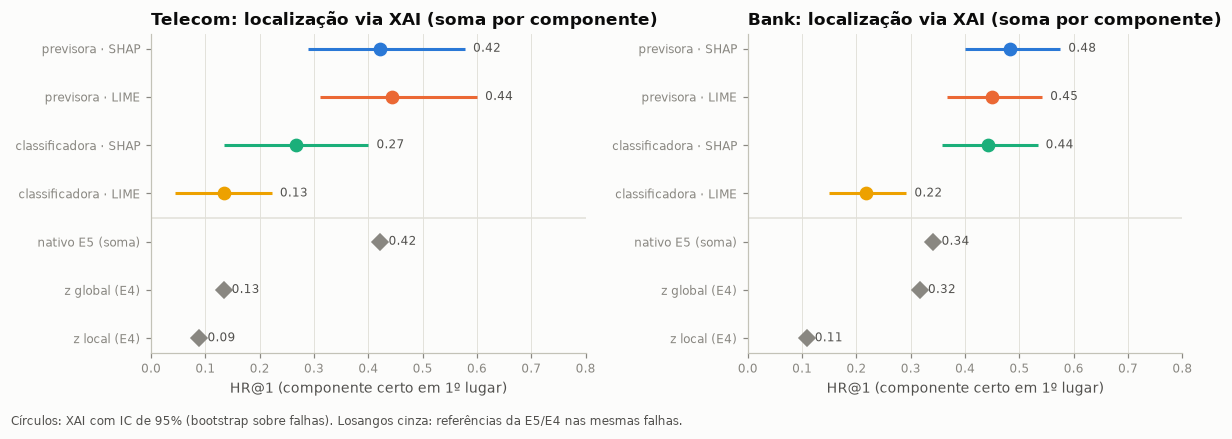

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, s in zip(axes, SYSTEMS, strict=True):
    loc = T[(s, "xai")]["localization"]
    labels = []
    for i, (key, (label, color)) in enumerate(COMBOS.items()):
        e = loc[f"{key}/sum"]["hr@1"]
        ax.errorbar(
            e["value"],
            i,
            xerr=[[e["value"] - e["ci_low"]], [e["ci_high"] - e["value"]]],
            fmt="o",
            color=color,
            ms=8,
            elinewidth=2,
            capsize=0,
        )
        ax.text(e["ci_high"] + 0.015, i, f"{e['value']:.2f}", va="center", fontsize=8, color=INK2)
        labels.append(label)
    for j, (name, r) in enumerate(RIVALS[s].items(), start=len(COMBOS)):
        v = rank_metrics(r)["HR@1"]
        ax.plot(v, j, "D", color=MUTED, ms=7)
        ax.text(v + 0.015, j, f"{v:.2f}", va="center", fontsize=8, color=INK2)
        labels.append(name)
    clean_y(ax, labels)
    ax.axhline(len(COMBOS) - 0.5, color=GRID, lw=1)
    ax.set_xlim(0, 0.8)
    ax.set_xlabel("HR@1 (componente certo em 1º lugar)")
    ax.set_title(f"{s}: localização via XAI (soma por componente)", loc="left")
fig.text(
    0.01,
    -0.03,
    "Círculos: XAI com IC de 95% (bootstrap sobre falhas). "
    "Losangos cinza: referências da E5/E4 nas mesmas falhas.",
    fontsize=8,
    color=INK2,
)
fig.tight_layout()
plt.show()

**Leitura.**

- **Telecom:** SHAP e LIME da previsora acertam o componente em 1º lugar em 42% e 44% das falhas, empatados com o ranqueamento nativo (0,42) e mais que o triplo do z-score (0,13). Antes do ADR 0019, com a pontuação na janela inteira, o SHAP da previsora ficava em 0,33.
- **Bank:** o SHAP da previsora é a melhor localização medida no projeto (HR@1 0,48, MRR 0,61), à frente do nativo (0,34) e do SHAP da classificadora (0,44). O LIME da classificadora é o pior método nos dois sistemas.

O gráfico seguinte mostra quais dessas diferenças são estatisticamente claras.

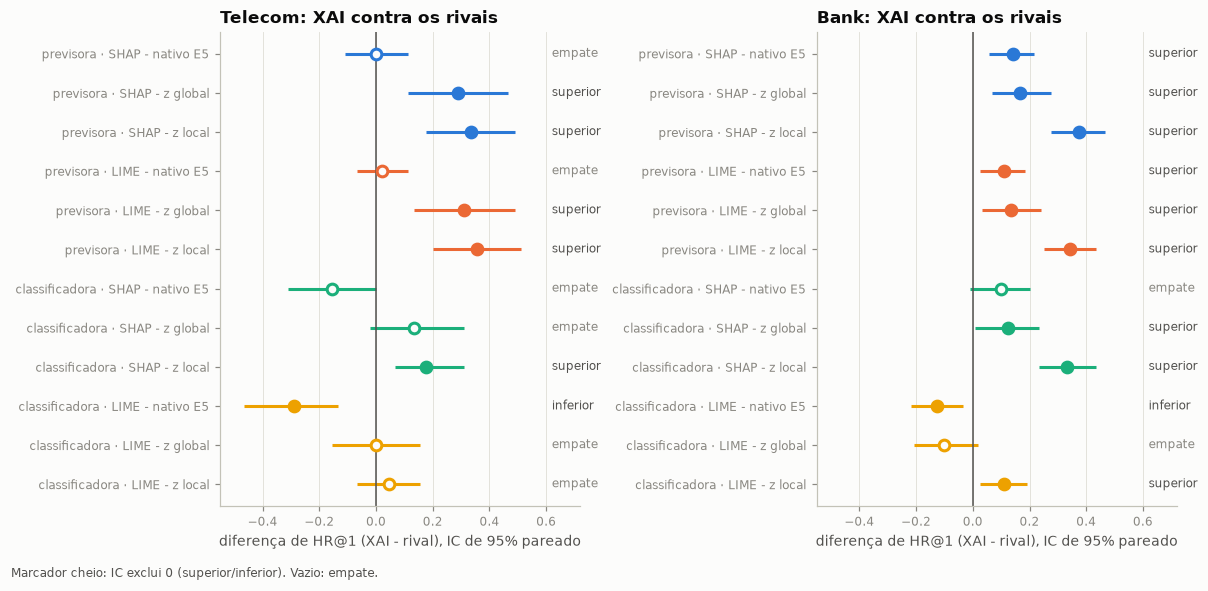

sistema,XAI,rival,métrica,diferença,veredito
str,str,str,str,str,str
"""Telecom""","""previsora · SHAP""","""nativo E5""","""HR@1""","""+0.000 [-0.111, +0.111]""","""empate"""
"""Telecom""","""previsora · SHAP""","""nativo E5""","""MRR""","""+0.041 [-0.038, +0.118]""","""empate"""
"""Telecom""","""previsora · SHAP""","""z global""","""HR@1""","""+0.289 [+0.111, +0.467]""","""superior"""
"""Telecom""","""previsora · SHAP""","""z global""","""MRR""","""+0.293 [+0.149, +0.435]""","""superior"""
"""Telecom""","""previsora · SHAP""","""z local""","""HR@1""","""+0.333 [+0.178, +0.489]""","""superior"""
…,…,…,…,…,…
"""Bank""","""classificadora · LIME""","""nativo E5""","""MRR""","""-0.096 [-0.162, -0.028]""","""inferior"""
"""Bank""","""classificadora · LIME""","""z global""","""HR@1""","""-0.100 [-0.208, +0.017]""","""empate"""
"""Bank""","""classificadora · LIME""","""z global""","""MRR""","""-0.049 [-0.130, +0.038]""","""empate"""


In [6]:
RIVAL_LABEL = {
    "lstm_nativo_soma": "nativo E5",
    "zscore_global": "z global",
    "zscore_local": "z local",
}
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharex=True)
for ax, s in zip(axes, SYSTEMS, strict=True):
    paired = [p for p in T[(s, "xai")]["paired"] if p["metric"] == "hr@1"]
    labels = []
    for i, p in enumerate(paired):
        key = p["xai"].rsplit("/", 1)[0]
        label, color = COMBOS[key]
        filled = p["verdict"] != "empate"
        ax.errorbar(
            p["value"],
            i,
            xerr=[[p["value"] - p["ci_low"]], [p["ci_high"] - p["value"]]],
            fmt="o",
            ms=7,
            color=color,
            mfc=color if filled else SURFACE,
            mew=2,
            elinewidth=2,
            capsize=0,
        )
        ax.text(0.62, i, p["verdict"], va="center", fontsize=8, color=INK2 if filled else MUTED)
        labels.append(f"{label} - {RIVAL_LABEL[p['rival']]}")
    ax.axvline(0, color=INK2, lw=1)
    clean_y(ax, labels)
    ax.set_xlim(-0.55, 0.72)
    ax.set_xlabel("diferença de HR@1 (XAI - rival), IC de 95% pareado")
    ax.set_title(f"{s}: XAI contra os rivais", loc="left")
fig.text(
    0.01,
    -0.02,
    "Marcador cheio: IC exclui 0 (superior/inferior). Vazio: empate.",
    fontsize=8,
    color=INK2,
)
fig.tight_layout()
plt.show()

display(
    pl.DataFrame(
        [
            {
                "sistema": s,
                "XAI": COMBOS[p["xai"].rsplit("/", 1)[0]][0],
                "rival": RIVAL_LABEL[p["rival"]],
                "métrica": p["metric"].upper(),
                "diferença": diff_text(p),
                "veredito": p["verdict"],
            }
            for s in SYSTEMS
            for p in T[(s, "xai")]["paired"]
        ]
    )
)

## 3. Sensibilidade à isenção de disponibilidade

A isenção dos KPIs de disponibilidade (`On_Off_State`, `ICMP_ping` etc.) foi decidida depois de ver os rótulos (ameaça nº 1). O controle `xai_sem_isencao` explica as LSTMs treinadas sem esses KPIs.

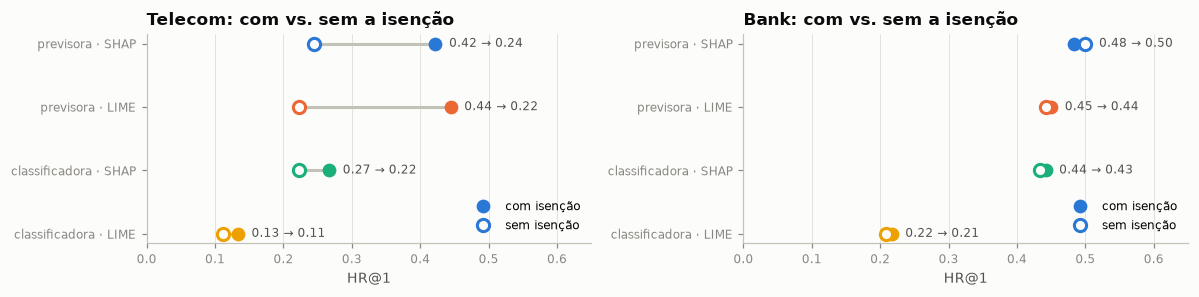

Telecom, sem isenção — vereditos pareados: {'empate': 18, 'superior': 5, 'inferior': 1}
Bank, sem isenção — vereditos pareados: {'superior': 20, 'inferior': 3, 'empate': 1}


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 2.8), sharex=True)
for ax, s in zip(axes, SYSTEMS, strict=True):
    labels = []
    for i, (key, (label, color)) in enumerate(COMBOS.items()):
        com = T[(s, "xai")]["localization"][f"{key}/sum"]["hr@1"]["value"]
        sem = T[(s, "xai_sem_isencao")]["localization"][f"{key}/sum"]["hr@1"]["value"]
        ax.plot([com, sem], [i, i], color=AXIS, lw=2, zorder=1)
        ax.plot(com, i, "o", color=color, ms=8, zorder=2, label="com isenção" if i == 0 else None)
        ax.plot(
            sem,
            i,
            "o",
            color=color,
            mfc=SURFACE,
            mew=2,
            ms=8,
            zorder=2,
            label="sem isenção" if i == 0 else None,
        )
        ax.text(
            max(com, sem) + 0.02, i, f"{com:.2f} → {sem:.2f}", va="center", fontsize=8, color=INK2
        )
        labels.append(label)
    clean_y(ax, labels)
    ax.set_xlim(0, 0.65)
    ax.set_xlabel("HR@1")
    ax.set_title(f"{s}: com vs. sem a isenção", loc="left")
    ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

for s in SYSTEMS:
    verdicts = Counter(p["verdict"] for p in T[(s, "xai_sem_isencao")]["paired"])
    print(f"{s}, sem isenção — vereditos pareados: {dict(verdicts)}")

**Leitura.**

- **Telecom:** sem a isenção, a localização via XAI cai quase pela metade (previsora · SHAP: 0,42 → 0,24), e a maioria das comparações pareadas vira empate. A previsora ainda supera o z local (HR@1 com SHAP; MRR com SHAP e LIME) e o z global (MRR com SHAP). Como no ranqueamento nativo da E5, o ganho de localização no Telecom vem em boa parte dos KPIs de disponibilidade.
- **Bank:** não há KPIs de disponibilidade, e os números praticamente não mudam.

## 4. Fidelidade: as explicações apontam o que move a saída?

- **Deleção:** os k atributos mais importantes são trocados, aos poucos (k = 1, 2, 5, 10, 20, 50), pela referência normal, e mede-se a média da curva de pontuação relativa à pontuação original. Quanto **menor**, mais fiel.
- **Comparação:** a mesma conta em 5 ordens aleatórias.

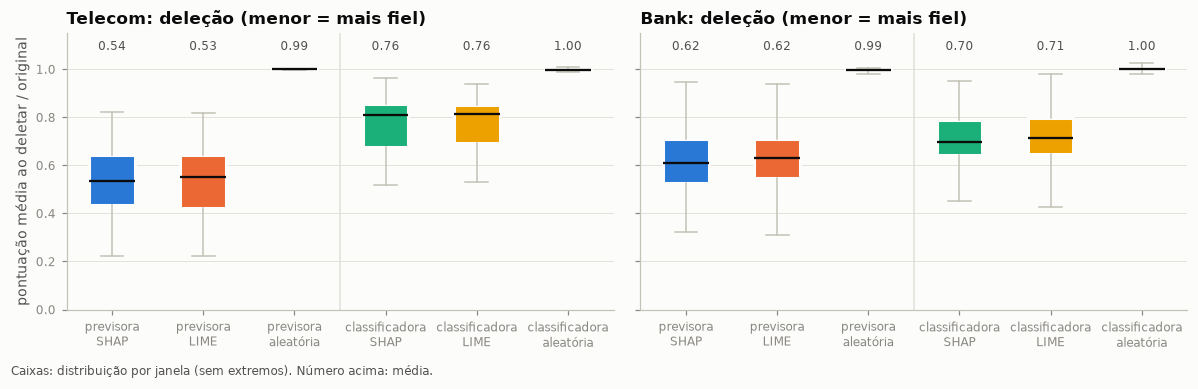

sistema,modelo,deletion_shap,deletion_lime,deletion_random,insertion_shap,insertion_lime,insertion_random
str,str,f64,f64,f64,f64,f64,f64
"""Telecom""","""previsora""",0.5374,0.5302,0.9938,0.6873,0.674,0.0413
"""Telecom""","""classificadora""",0.7566,0.76,0.9988,0.8069,0.8661,0.3277
"""Bank""","""previsora""",0.6185,0.6247,0.9944,0.6586,0.6465,0.0601
"""Bank""","""classificadora""",0.6954,0.7051,0.9998,3.4708,4.4899,1.4062


In [8]:
def quality(system, name="xai"):
    return pl.read_csv(ART[(system, name)] / "xai_quality.csv", infer_schema_length=None)


fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, s in zip(axes, SYSTEMS, strict=True):
    q = quality(s).filter(pl.col("seed_pair").is_null())
    data, colors, labels = [], [], []
    for model in ("lstm_forecast", "lstm_classifier"):
        sub = q.filter(pl.col("model") == model)
        for explainer in ("shap", "lime", "random"):
            data.append(sub[f"deletion_{explainer}"].drop_nulls().to_numpy())
            colors.append(COMBOS[f"{model}/{explainer}"][1] if explainer != "random" else MUTED)
            name = explainer.upper() if explainer != "random" else "aleatória"
            labels.append(f"{MODEL_LABEL[model]}\n{name}")
    box = ax.boxplot(
        data,
        widths=0.5,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": INK, "lw": 1.5},
        whiskerprops={"color": AXIS},
        capprops={"color": AXIS},
    )
    for patch, color in zip(box["boxes"], colors, strict=True):
        patch.set(facecolor=color, edgecolor=SURFACE, linewidth=2)
    for i, d in enumerate(data, start=1):
        ax.text(i, 1.08, f"{np.mean(d):.2f}", ha="center", fontsize=8, color=INK2)
    ax.set_xticks(range(1, len(labels) + 1), labels)
    ax.grid(axis="x", visible=False)
    ax.axvline(3.5, color=GRID, lw=1)
    ax.set_ylim(0, 1.15)
    ax.set_title(f"{s}: deleção (menor = mais fiel)", loc="left")
axes[0].set_ylabel("pontuação média ao deletar / original")
fig.text(
    0.01,
    -0.02,
    "Caixas: distribuição por janela (sem extremos). Número acima: média.",
    fontsize=8,
    color=INK2,
)
fig.tight_layout()
plt.show()

display(
    pl.DataFrame(
        [
            {
                "sistema": s,
                "modelo": MODEL_LABEL[m],
                **{
                    k: T[(s, "xai")]["quality"][m][k]
                    for k in (
                        "deletion_shap",
                        "deletion_lime",
                        "deletion_random",
                        "insertion_shap",
                        "insertion_lime",
                        "insertion_random",
                    )
                },
            }
            for s in SYSTEMS
            for m in ("lstm_forecast", "lstm_classifier")
        ]
    )
)

**Leitura.**

- **Deleção:** nos dois modelos e sistemas, retirar os atributos que SHAP ou LIME apontam derruba a pontuação. A curva fica em média em 53% a 76% da original, contra cerca de 100% em ordem aleatória. As explicações são **fiéis**: apontam atributos de que a saída realmente depende.
- **Inserção** (tabela): os k atributos mais importantes são inseridos na referência normal, e a métrica é a média da curva relativa à janela completa (maior = mais fiel).
  - Funciona na previsora (0,65–0,69 contra 0,04–0,06 aleatória) e na classificadora do Telecom.
  - Na classificadora do Bank passa de 1, o que não faz sentido como fração. A célula abaixo mostra por quê.

In [9]:
# Diagnostic: probability the Bank classifier gives to the oracle windows vs to the normal reference
from tcc_rca.evaluation.baselines import row_of
from tcc_rca.evaluation.lstm import Experiment, _masks
from tcc_rca.evaluation.xai import FoldModels, _filled
from tcc_rca.explain.functions import evaluate
from tcc_rca.models.lstm.data import window_tensor


def classifier_vs_reference(system):
    config = load_config(*SYSTEM_CONFIGS[system], "configs/experiment/xai.yaml")
    lstm_t = read_json(TABLES / f"lstm_{system}_lstm.json")
    models_dir = Path("experiments") / lstm_t["run_dir"] / "artifacts" / "models"
    exp = Experiment(config, TABLES)
    fx, fr = [], []
    for fold in exp.folds:
        fd = exp.fold_data(fold)
        fm = FoldModels(
            models_dir,
            fold.index,
            0,
            lstm_t,
            "cpu",
            config.lstm.score_top_k,
            config.tasks.score_minutes,
        )
        inputs = exp.inputs(fd, lstm_t["selection"]["forecaster"]["normalization"])
        ref = np.median(
            _filled(exp.tensors(fd, inputs, _masks(fd)["train_normal"])), axis=0
        ).astype(np.float32)
        ends = np.array(
            [
                row_of(
                    exp.minute_to_row,
                    f.start_utc.timestamp() / 60.0 + exp.t.detection_tolerance_minutes,
                )
                for f in exp.tested(fold)
            ],
            dtype=np.int64,
        )
        module = fm.modules["lstm_classifier"]
        fx += evaluate(
            module, _filled(window_tensor(inputs.matrix, ends, exp.t.window_minutes))
        ).tolist()
        fr += [float(evaluate(module, ref[None])[0])] * len(ends)
    return np.array(fx), np.array(fr)


diag = {s: classifier_vs_reference(s) for s in SYSTEMS}
display(
    pl.DataFrame(
        [
            {
                "sistema": s,
                "P(falha) janela-oráculo, mediana": round(float(np.median(fx)), 3),
                "P(falha) referência normal, mediana": round(float(np.median(fr)), 3),
                "falhas com P < referência": f"{np.mean(fx < fr):.0%}",
            }
            for s, (fx, fr) in diag.items()
        ]
    )
)

sistema,"P(falha) janela-oráculo, mediana","P(falha) referência normal, mediana",falhas com P < referência
str,f64,f64,str
"""Telecom""",0.563,0.117,"""0%"""
"""Bank""",0.361,0.434,"""49%"""


**Por que a inserção não serve para a classificadora do Bank.** Ela dá à janela de referência "normal" uma probabilidade de falha **maior** que a de metade das janelas de falha. A inserção parte da referência e é dividida pela pontuação da janela completa, então a curva passa de 1.

A referência normal não é neutra para esse modelo, coerente com a detecção fraca da classificadora no Bank (AUC-PR 0,22). A deleção não depende desse ponto de partida e continua válida.

## 5. Estabilidade e concordância

Uma explicação útil ao agente deve ser **reprodutível**: o mesmo modelo, treinado com outra seed, ou a janela de um minuto ao lado, deveria apontar KPIs parecidos. Medidas (top-10 KPIs por importância):

- **Jaccard:** sobreposição dos conjuntos (1 = iguais);
- **Kendall:** concordância da ordem (1 = mesma ordem; negativo = ordem invertida).

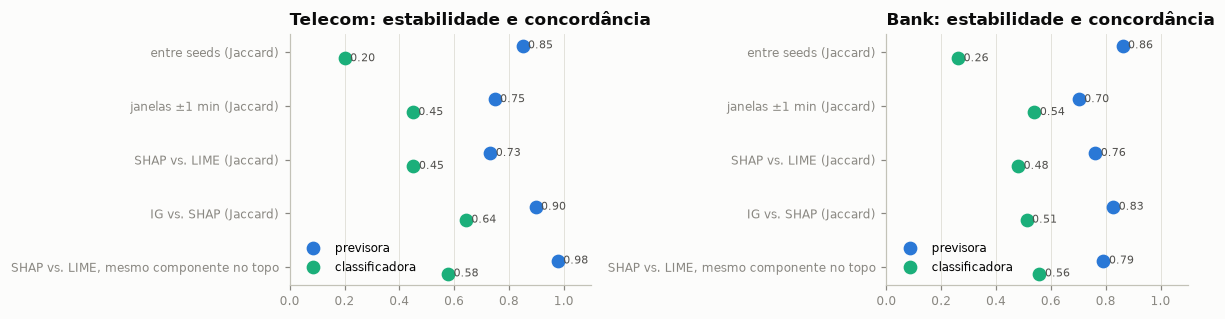

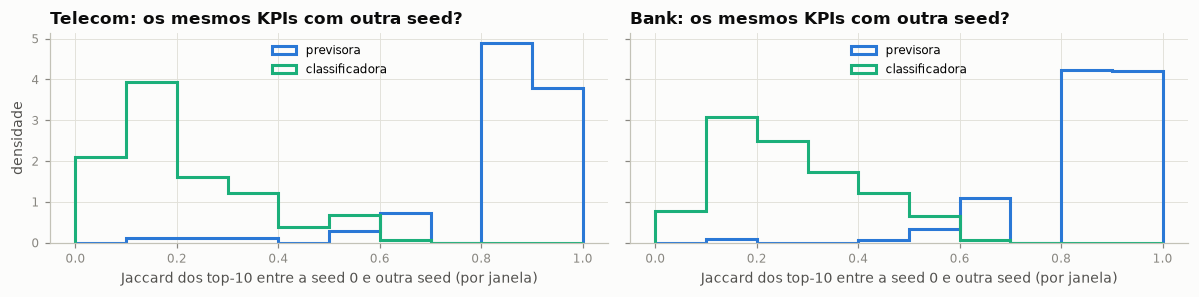

sistema,modelo,seed_jaccard,seed_kendall,neighbour_jaccard,shap_lime_jaccard,shap_lime_kendall,ig_shap_jaccard,ig_shap_kendall,top_component_agree
str,str,f64,f64,f64,f64,f64,f64,f64,f64
"""Telecom""","""previsora""",0.8493,0.7939,0.7475,0.7318,0.7354,0.8967,0.8632,0.9778
"""Telecom""","""classificadora""",0.2005,-0.2561,0.4491,0.4515,0.1664,0.6425,0.4724,0.5778
"""Bank""","""previsora""",0.8612,0.7981,0.7013,0.7619,0.7059,0.8272,0.8001,0.7917
"""Bank""","""classificadora""",0.2614,-0.1369,0.5396,0.4803,0.2508,0.5111,0.3018,0.5583


In [10]:
METRICS = {
    "seed_jaccard": "entre seeds (Jaccard)",
    "neighbour_jaccard": "janelas ±1 min (Jaccard)",
    "shap_lime_jaccard": "SHAP vs. LIME (Jaccard)",
    "ig_shap_jaccard": "IG vs. SHAP (Jaccard)",
    "top_component_agree": "SHAP vs. LIME, mesmo componente no topo",
}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.0), sharex=True)
for ax, s in zip(axes, SYSTEMS, strict=True):
    qual = T[(s, "xai")]["quality"]
    for model, offset in (("lstm_forecast", -0.12), ("lstm_classifier", 0.12)):
        vals = [qual[model][k] for k in METRICS]
        ax.plot(
            vals,
            np.arange(len(METRICS)) + offset,
            "o",
            color=MODEL_COLOR[model],
            ms=8,
            label=MODEL_LABEL[model],
        )
        for i, v in enumerate(vals):
            ax.text(v + 0.02, i + offset, f"{v:.2f}", va="center", fontsize=7, color=INK2)
    clean_y(ax, list(METRICS.values()))
    ax.set_xlim(0, 1.1)
    ax.set_title(f"{s}: estabilidade e concordância", loc="left")
    ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 2.8), sharey=True)
bins = np.linspace(0, 1, 11)
for ax, s in zip(axes, SYSTEMS, strict=True):
    q = quality(s).filter(pl.col("seed_pair").is_not_null())
    for model in ("lstm_forecast", "lstm_classifier"):
        ax.hist(
            q.filter(pl.col("model") == model)["seed_jaccard"].to_numpy(),
            bins=bins,
            histtype="step",
            lw=2,
            color=MODEL_COLOR[model],
            label=MODEL_LABEL[model],
            density=True,
        )
    ax.set_xlabel("Jaccard dos top-10 entre a seed 0 e outra seed (por janela)")
    ax.set_title(f"{s}: os mesmos KPIs com outra seed?", loc="left")
    ax.legend(loc="upper center")
axes[0].set_ylabel("densidade")
fig.tight_layout()
plt.show()

display(
    pl.DataFrame(
        [
            {
                "sistema": s,
                "modelo": MODEL_LABEL[m],
                **{
                    k: T[(s, "xai")]["quality"][m][k]
                    for k in (
                        "seed_jaccard",
                        "seed_kendall",
                        "neighbour_jaccard",
                        "shap_lime_jaccard",
                        "shap_lime_kendall",
                        "ig_shap_jaccard",
                        "ig_shap_kendall",
                        "top_component_agree",
                    )
                },
            }
            for s in SYSTEMS
            for m in ("lstm_forecast", "lstm_classifier")
        ]
    )
)

**Leitura.** É aqui que os dois modelos se separam.

- **Previsora:** as explicações são estáveis entre seeds (Jaccard ≈ 0,85) e entre minutos vizinhos (≈ 0,7–0,75), e SHAP, LIME e IG concordam. Com a pontuação nos últimos 6 minutos (ADR 0019), a estabilidade entre seeds subiu e a entre minutos vizinhos caiu um pouco: a explicação acompanha mais de perto o que muda no fim da janela.
- **Classificadora:** com outra seed, quase todos os 10 KPIs mais importantes mudam (Jaccard ≈ 0,2–0,3), e a ordem chega a se inverter (Kendall negativo). Modelos com o mesmo desempenho de detecção "usam" KPIs diferentes: é o efeito Rashomon (ameaça nº 12).
- **Divergência SHAP × LIME na classificadora:** os dois métodos medem coisas diferentes. O SHAP integra gradientes contra uma distribuição de janelas normais; o LIME desliga séries inteiras e ajusta um modelo linear, que aproxima mal uma probabilidade saturada e com interações. O IG, que é baseado em gradiente como o SHAP, concorda mais com ele do que o LIME.

**Decisão (ADR 0016, ameaça nº 11).** Por isso, nos pacotes de evidência, a classificadora escolhe a janela e dá o alarme, e as atribuições citáveis vêm da previsora.

## 6. Categoria de motivo sugerida

A categoria sugerida é a categoria de KPI (CPU, memória, rede, disco…) com maior soma de atribuições positivas. O acerto é medido contra o mapa motivo → categorias fixado antes de medir (`explain.reason_categories`), e comparado com duas referências que não olham a janela:

- **prior de treino:** a categoria mais frequente nas falhas de treino;
- **uniforme:** uma categoria sorteada.

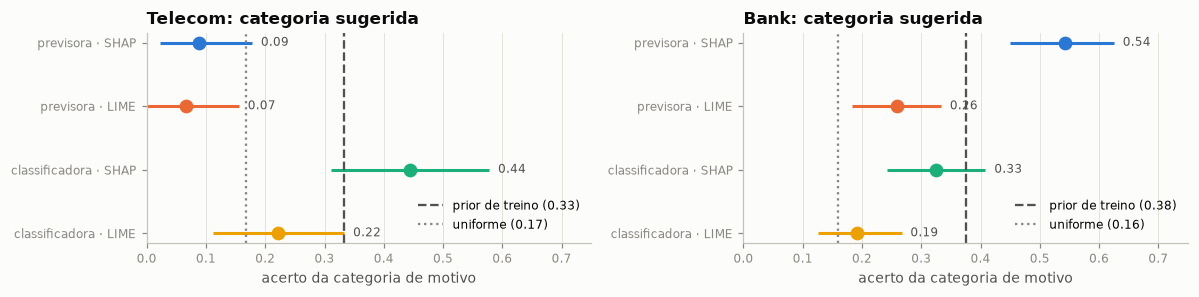

sistema,XAI,diferença vs. prior,veredito
str,str,str,str
"""Telecom""","""previsora · SHAP""","""-0.244 [-0.422, -0.067]""","""inferior"""
"""Telecom""","""previsora · LIME""","""-0.267 [-0.422, -0.111]""","""inferior"""
"""Telecom""","""classificadora · SHAP""","""+0.111 [-0.133, +0.333]""","""empate"""
"""Telecom""","""classificadora · LIME""","""-0.111 [-0.311, +0.089]""","""empate"""
"""Bank""","""previsora · SHAP""","""+0.167 [+0.042, +0.283]""","""superior"""
"""Bank""","""previsora · LIME""","""-0.117 [-0.242, +0.008]""","""empate"""
"""Bank""","""classificadora · SHAP""","""-0.050 [-0.192, +0.083]""","""empate"""
"""Bank""","""classificadora · LIME""","""-0.183 [-0.317, -0.050]""","""inferior"""


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 2.8), sharex=True)
for ax, s in zip(axes, SYSTEMS, strict=True):
    hits = T[(s, "xai")]["category_hit"]
    labels = []
    for i, (key, (label, color)) in enumerate(COMBOS.items()):
        e = hits[key]
        ax.errorbar(
            e["value"],
            i,
            xerr=[[e["value"] - e["ci_low"]], [e["ci_high"] - e["value"]]],
            fmt="o",
            color=color,
            ms=8,
            elinewidth=2,
            capsize=0,
        )
        ax.text(e["ci_high"] + 0.015, i, f"{e['value']:.2f}", va="center", fontsize=8, color=INK2)
        labels.append(label)
    prior, unif = hits["referência/prior_treino"]["value"], hits["referência/uniforme"]["value"]
    ax.axvline(prior, color=INK2, lw=1.5, ls="--", label=f"prior de treino ({prior:.2f})")
    ax.axvline(unif, color=MUTED, lw=1.5, ls=":", label=f"uniforme ({unif:.2f})")
    ax.legend(loc="lower right")
    clean_y(ax, labels)
    ax.set_xlim(0, 0.75)
    ax.set_xlabel("acerto da categoria de motivo")
    ax.set_title(f"{s}: categoria sugerida", loc="left")
fig.tight_layout()
plt.show()

display(
    pl.DataFrame(
        [
            {
                "sistema": s,
                "XAI": COMBOS[p["xai"]][0],
                "diferença vs. prior": diff_text(p),
                "veredito": p["verdict"],
            }
            for s in SYSTEMS
            for p in T[(s, "xai")]["category_paired"]
        ]
    )
)

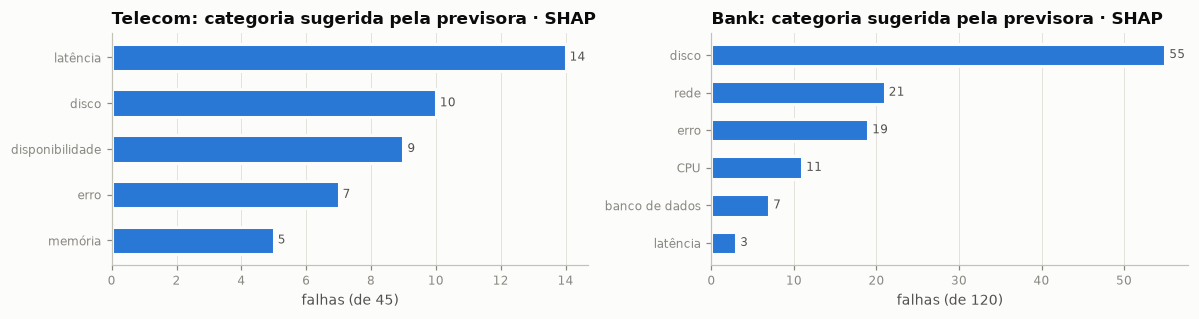

reason,latência,disco,memória,erro,disponibilidade
str,u32,u32,u32,u32,u32
"""CPU fault""",9,5,1,0,0
"""db close""",0,1,0,2,1
"""db connection limit""",0,2,1,3,0
"""network delay""",2,2,1,1,7
"""network loss""",3,0,2,1,1


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.0))
for ax, s in zip(axes, SYSTEMS, strict=True):
    cats = pl.read_csv(ART[(s, "xai")] / "xai_categories.csv")
    sub = cats.filter((pl.col("model") == "lstm_forecast") & (pl.col("explainer") == "shap"))
    counts = Counter(
        x if x is not None else "nenhuma" for x in sub["suggested"].to_list()
    ).most_common(6)
    labels, values = zip(*counts, strict=True)
    y = np.arange(len(labels))
    ax.barh(y, values, height=0.6, color=SLOTS[0], edgecolor=SURFACE, linewidth=2)
    for yi, v in zip(y, values, strict=True):
        ax.text(v, yi, f" {v}", va="center", fontsize=8, color=INK2)
    clean_y(ax, list(labels))
    ax.set_xlabel(f"falhas (de {sub.height})")
    ax.set_title(f"{s}: categoria sugerida pela previsora · SHAP", loc="left")
fig.tight_layout()
plt.show()

tel = pl.read_csv(ART[("Telecom", "xai")] / "xai_categories.csv").filter(
    (pl.col("model") == "lstm_forecast") & (pl.col("explainer") == "shap")
)
display(
    tel.group_by("reason", "suggested")
    .len()
    .sort("reason", "len", descending=[False, True])
    .pivot(on="suggested", index="reason", values="len")
    .fill_null(0)
)

**Leitura.** A categoria sugerida supera a categoria mais frequente do treino em um único caso: o SHAP da previsora no Bank (0,54 contra 0,38, superior no pareado), resultado que apareceu com a pontuação nos últimos minutos (ADR 0019). No Telecom, a da previsora fica abaixo do prior (0,09 contra 0,33). A soma por categoria favorece categorias com muitos KPIs.

A agregação não foi trocada depois desses resultados, para não ajustar no teste (ameaça nº 13), e a categoria continua fora do que o agente vê (ADR 0017), porque o ganho não se repete no Telecom. Na E7, o agente deve raciocinar sobre os KPIs individuais do pacote, e não adotar a categoria sugerida como motivo.

## 7. Pacotes de evidência, do valor bruto à atribuição

Os pacotes abaixo são do Telecom, como o agente da E7 vai recebê-los. Cada um traz:

- os componentes `C#` e os KPIs `K#` citáveis;
- o ranqueamento nativo `N#`;
- o alarme do detector;
- em cada KPI, o valor bruto no instante de pico e a mediana normal.

O gabarito aparece aqui **só para a análise**: ele não está no pacote, e o agente não tem acesso a ele.

São dois exemplos, escolhidos por regra fixa para não escolher a dedo:

- **A:** o primeiro pacote, em ordem de consulta, com alarme disparado;
- **B:** o primeiro pacote com alarme cujo componente C1 coincide com o gabarito (um acerto, escolhido por ser acerto).

In [13]:
from tcc_rca.evaluation.xai import Explainer
from tcc_rca.ingestion.timeutil import OPENRCA_TZ

config = load_config("configs/base.yaml", "configs/experiment/xai.yaml")
lstm_t = read_json(TABLES / "lstm_Telecom_lstm.json")
exp = Experiment(config, TABLES)
times = exp.values["time_utc"].to_list()
failures = read_failures(Path("data/raw/openrca/Telecom/record.csv"))
EVIDENCE = Path(T[("Telecom", "xai")]["evidence_dir"])
packages = [read_json(p) for p in sorted(EVIDENCE.glob("query_*.json"))]


def truth_of(pkg):
    q0, q1 = (parse_local(t) for t in pkg["query_window_local"])
    return [f for f in failures if q0 <= f.start_utc < q1]


def describe(pkg):
    q_start, q_end = pkg["query_window_local"]
    print(f"consulta {pkg['query_row']} ({pkg['task_index']}): {q_start} a {q_end} (UTC+8)")
    print(f"janela explicada: {pkg['window_local'][0]} a {pkg['window_local'][1]}")
    score, threshold = pkg["detector_score"], pkg["detector_threshold"]
    print(f"detector {pkg['detector']}: pontuação {score:.3f}, limiar {threshold:.3f}")
    print(
        f"atribuições de: {pkg['explained_model']}; categoria sugerida: {pkg['suggested_category']}"
    )
    for f in truth_of(pkg):
        onset = utc_to_local_str(f.start_utc)
        print(f"gabarito (só análise): {onset} · componente {f.component} · motivo {f.reason}")
    display(pl.DataFrame(pkg["components"]))
    cols = ["id", "feature", "category", "shap_attribution", "lime_weight", "peak_time_local"]
    cols += ["raw_value_at_peak", "normal_median", "normalized_value_at_peak"]
    display(pl.DataFrame(pkg["kpis"]).select(cols))
    display(pl.DataFrame(pkg["native_ranking"]))


series = pl.read_parquet("data/processed/Telecom/series.parquet")


def plot_series(pkg, n=3):
    w0, w1 = (parse_local(t) for t in pkg["window_local"])
    day = series.filter(pl.col("time_utc") == w1)["day"][0]
    context = series.filter(
        (pl.col("day") == day)
        & (pl.col("time_utc") >= w0 - timedelta(minutes=40))
        & (pl.col("time_utc") <= w1 + timedelta(minutes=10))
    )
    onsets = [f.start_utc for f in truth_of(pkg)]
    fig, axes = plt.subplots(n, 1, figsize=(10, 2.0 * n), sharex=True)
    for ax, k in zip(axes, pkg["kpis"][:n], strict=True):
        t = context["time_utc"].to_list()
        ax.axvspan(w0, w1, color=GRID, alpha=0.6, lw=0)
        for onset in onsets:
            ax.axvline(onset, color=INK2, lw=1, ls=":")
        ax.plot(t, context[k["feature"]].to_numpy(), color=SLOTS[0], lw=2)
        if k["normal_median"] is not None:
            ax.axhline(k["normal_median"], color=MUTED, lw=1.5, ls="--")
            ax.text(
                t[0], k["normal_median"], " mediana normal", fontsize=7, color=MUTED, va="bottom"
            )
        peak = parse_local(k["peak_time_local"])
        unit = "" if k["unit"] == "desconhecida" else f" {k['unit']}"
        ax.plot(peak, k["raw_value_at_peak"], "o", color=SLOTS[0], ms=8, mec=SURFACE, mew=2)
        ax.text(
            peak,
            k["raw_value_at_peak"],
            f"  {k['raw_value_at_peak']:g}{unit}",
            fontsize=8,
            color=INK2,
            va="center",
        )
        ax.set_title(f"{k['id']} · {k['feature']} ({k['category']})", loc="left", fontsize=9)
        ax.grid(axis="x", visible=False)
    axes[-1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=OPENRCA_TZ))
    axes[-1].set_xlabel(
        "horário UTC+8 · faixa cinza = janela explicada · pontilhado = início real da falha"
    )
    fig.tight_layout()
    plt.show()


def plot_shap(pkg):
    end_row = times.index(parse_local(pkg["window_local"][1]))
    fold = next(f for f in exp.folds if f.test_day == exp.day_arr[end_row])
    fd = exp.fold_data(fold)
    models_dir = Path("experiments") / lstm_t["run_dir"] / "artifacts" / "models"
    fm = FoldModels(
        models_dir,
        fold.index,
        config.explain.explained_seed,
        lstm_t,
        "cpu",
        config.lstm.score_top_k,
        config.tasks.score_minutes,
    )
    inputs = exp.inputs(fd, lstm_t["selection"]["forecaster"]["normalization"])
    train_normal = exp.tensors(fd, inputs, _masks(fd)["train_normal"])
    rng = np.random.default_rng(config.experiment.seed + fold.index)
    size = min(config.explain.background_windows, train_normal.shape[0])
    pick = rng.choice(train_normal.shape[0], size=size, replace=False)
    reference = np.median(_filled(train_normal), axis=0).astype(np.float32)
    xp = Explainer(config, _filled(train_normal[np.sort(pick)]), reference)
    window = window_tensor(inputs.matrix, np.array([end_row]), exp.t.window_minutes)[0]
    attr = xp.shap(fm.modules["lstm_forecast"], window, config.experiment.seed + fold.index)

    idx = [fd.kept.index(k["feature"]) for k in pkg["kpis"]]
    expected = np.array([k["shap_attribution"] for k in pkg["kpis"]])
    print(
        "SHAP recalculado igual ao do pacote:",
        np.allclose(attr.sum(axis=0)[idx], expected, atol=1e-5),
    )
    m = np.abs(attr[:, idx]).max()
    fig, ax = plt.subplots(figsize=(10, 3.6))
    im = ax.imshow(
        attr[:, idx].T, aspect="auto", cmap=DIVERGING, vmin=-m, vmax=m, interpolation="nearest"
    )
    ax.set_yticks(range(len(idx)), [f"{k['id']} · {k['feature']}" for k in pkg["kpis"]])
    first = end_row - exp.t.window_minutes + 1
    minutes = [utc_to_local_str(times[first + i])[11:16] for i in range(exp.t.window_minutes)]
    ax.set_xticks(range(0, len(minutes), 2), minutes[::2])
    ax.set_xlabel("minuto da janela (UTC+8)")
    ax.grid(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
    cb.set_label("contribuição SHAP para a pontuação", fontsize=8)
    cb.outline.set_visible(False)
    ax.set_title(
        "Onde, no tempo, a previsora reagiu (vermelho = empurra a pontuação para cima)", loc="left"
    )
    fig.tight_layout()
    plt.show()


example_a = next(p for p in packages if p["alarm"])
example_b = next(
    p
    for p in packages
    if p["alarm"] and any(f.component == p["components"][0]["component"] for f in truth_of(p))
)

### Exemplo A: primeiro pacote com alarme (um erro)

consulta 10 (task_1): 2020-05-23 00:00:00 a 2020-05-23 00:30:00 (UTC+8)
janela explicada: 2020-05-23 00:06:00 a 2020-05-23 00:25:00
detector lstm_classifier: pontuação 0.515, limiar 0.499
atribuições de: lstm_forecast; categoria sugerida: memória
gabarito (só análise): 2020-05-23 00:05:00 · componente docker_004 · motivo CPU fault


id,component,rank,shap_weight,lime_weight
str,str,i64,f64,f64
"""C1""","""os_019""",1,17.834305,20.747132
"""C2""","""os_008""",2,10.762528,15.252958
"""C3""","""os_018""",3,7.60736,12.304863
"""C4""","""os_012""",4,6.480304,9.47499
"""C5""","""db_003""",5,5.499758,7.784551


id,feature,category,shap_attribution,lime_weight,peak_time_local,raw_value_at_peak,normal_median,normalized_value_at_peak
str,str,str,f64,f64,str,f64,f64,f64
"""K1""","""os_008::Disk_svctm""","""disco""",10.730583,10.559234,"""2020-05-23 00:25:00""",1.85,0.0,50.0
"""K2""","""os_019::Shared_memory""","""memória""",10.170425,10.056745,"""2020-05-23 00:25:00""",22904.0,72068.0,50.0
"""K3""","""os_019::Page_pi""","""memória""",7.591725,7.072736,"""2020-05-23 00:25:00""",18.193163,0.0,50.0
"""K4""","""os_012::Sent_packets""","""rede""",6.449087,6.262984,"""2020-05-23 00:25:00""",0.0,55.0,-50.0
"""K5""","""db_003::DFParaWrite_Per_Sec""","""disco""",5.404756,4.500406,"""2020-05-23 00:25:00""",33.54,1.47,27.2764
"""K6""","""os_018::Memory_free""","""memória""",4.868623,4.836092,"""2020-05-23 00:25:00""",72.329685,67.393894,-2.858
"""K7""","""db_001::LFParaWrite_Per_Sec""","""disco""",3.295362,3.510841,"""2020-05-23 00:13:00""",46.24,1.48,50.0
"""K8""","""os_018::Shared_memory""","""memória""",1.417556,1.331954,"""2020-05-23 00:16:00""",22896.0,96636.0,50.0
"""K9""","""os_018::Cache_used""","""memória""",1.274932,0.968464,"""2020-05-23 00:15:00""",1.996014,5.100258,3.064


id,component,rank,forecast_error_sum
str,str,i64,f64
"""N1""","""os_018""",1,1081.70752
"""N2""","""os_003""",2,940.413574
"""N3""","""os_019""",3,932.274658
"""N4""","""os_004""",4,860.288452
"""N5""","""os_005""",5,834.090881


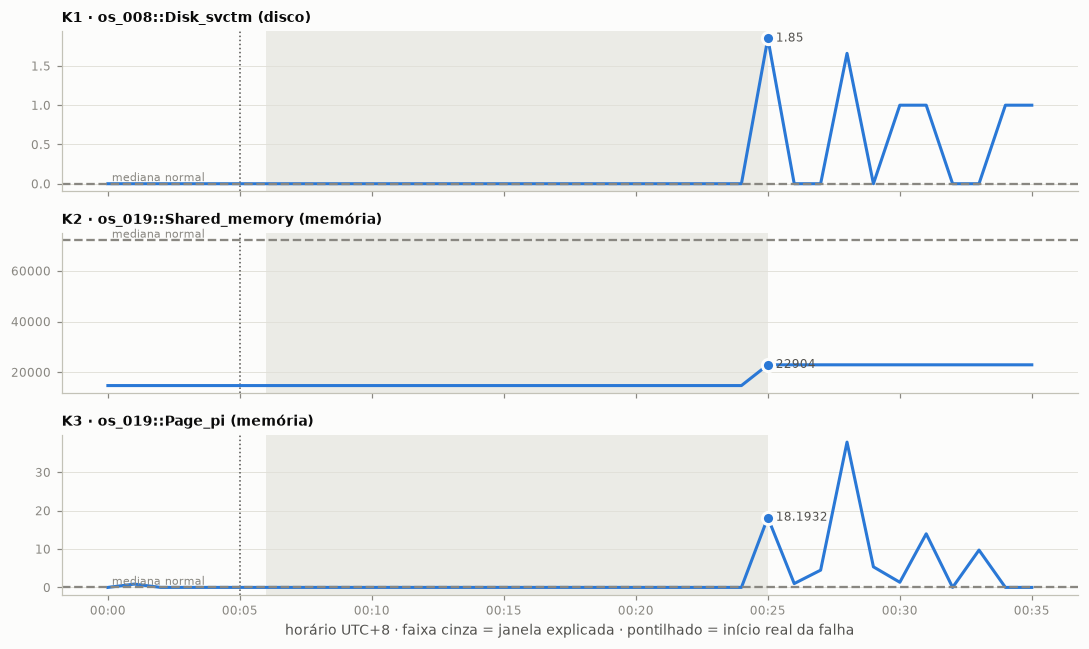

SHAP recalculado igual ao do pacote: True


/Users/febagnatori/Documents/Unifesp/TCC/TCC_Project/TCC_AI/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


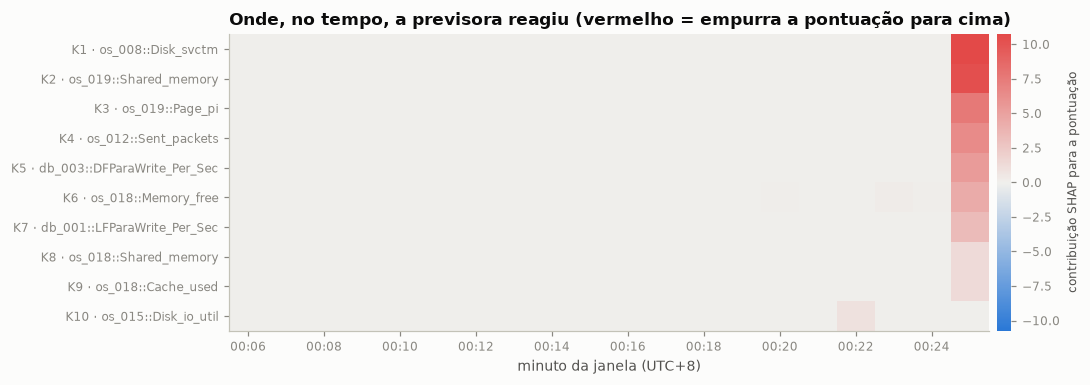

In [14]:
describe(example_a)
plot_series(example_a)
plot_shap(example_a)

**Leitura do exemplo A.** O gabarito é uma falha de CPU no contêiner `docker_004` (hospedado no `os_020`), iniciada às 00:05.

- **O que o pacote aponta:** o `os_019` em C1 (memória compartilhada e paginação) e o `os_008` em C2 (tempo de serviço de disco), todos com pico às 00:25, o último minuto da janela, 20 minutos depois do início da falha. O ranqueamento nativo aponta o `os_018` em N1.
- **Posição do componente certo:** nas janelas-oráculo, o `docker_004` fica perto da 50ª posição em todos os métodos (48ª a 55ª). Essa falha começa no 5º minuto do dia, e a janela-oráculo é a primeira janela completa do dia (ADR 0019).
- **Leitura honesta:** o detector disparou com razão (algo anormal aconteceu na janela), mas aquilo a que o modelo reagiu não é a causa raiz. É exatamente o caso que a ameaça nº 14 descreve.

**Mapa de calor.** A atribuição se concentra num único minuto porque a pontuação da previsora é o **máximo** dos últimos 6 minutos. O gradiente só passa pelo minuto de maior erro, e o SHAP herda essa estrutura.

### Exemplo B: primeiro pacote com alarme em que C1 é o componente certo

consulta 14 (task_1): 2020-05-23 03:30:00 a 2020-05-23 04:00:00 (UTC+8)
janela explicada: 2020-05-23 03:22:00 a 2020-05-23 03:41:00
detector lstm_classifier: pontuação 0.571, limiar 0.499
atribuições de: lstm_forecast; categoria sugerida: erro
gabarito (só análise): 2020-05-23 03:36:00 · componente os_021 · motivo network delay


id,component,rank,shap_weight,lime_weight
str,str,i64,f64,f64
"""C1""","""os_021""",1,166.346443,168.134685
"""C2""","""osb_001""",2,93.174417,91.209329
"""C3""","""db_004""",3,3.2042,8.134226
"""C4""","""os_002""",4,1.607997,7.573359
"""C5""","""db_002""",5,1.057101,11.495768


id,feature,category,shap_attribution,lime_weight,peak_time_local,raw_value_at_peak,normal_median,normalized_value_at_peak
str,str,str,f64,f64,str,f64,f64,f64
"""K1""","""osb_001::succee_rate""","""erro""",93.169991,90.121709,"""2020-05-23 03:36:00""",0.9,1.0,-50.0
"""K2""","""os_021::trace_error_rate""","""erro""",84.948303,82.259084,"""2020-05-23 03:36:00""",0.227273,0.0,50.0
"""K3""","""os_021::ICMP_ping""","""disponibilidade""",80.690323,76.84471,"""2020-05-23 03:36:00""",0.0,1.0,-50.0
"""K4""","""db_004::PGA_used_total""","""memória""",3.179869,1.716981,"""2020-05-23 03:22:00""",4.0,5.0,-2.407
"""K5""","""os_002::Cache_used""","""memória""",1.473662,0.839619,"""2020-05-23 03:33:00""",8.562283,8.417553,-3.0082
"""K6""","""db_002::MEM_Used_Pct""","""memória""",1.010981,-0.783099,"""2020-05-23 03:36:00""",49.515518,49.370841,2.5765
"""K7""","""os_017::Memory_available_pct""","""memória""",0.602903,-0.23732,"""2020-05-23 03:34:00""",93.6,92.68,-2.0044
"""K8""","""os_003::Received_queue""","""rede""",0.542774,0.192026,"""2020-05-23 03:35:00""",76.0,0.0,50.0
"""K9""","""os_021::Outgoing_network_traff…","""rede""",0.453136,-0.571207,"""2020-05-23 03:36:00""",0.004773,0.068379,-4.2132


id,component,rank,forecast_error_sum
str,str,i64,f64
"""N1""","""os_021""",1,2045.132935
"""N2""","""os_020""",2,1235.691895
"""N3""","""os_018""",3,1229.994019
"""N4""","""osb_001""",4,1013.902893
"""N5""","""os_006""",5,818.794983


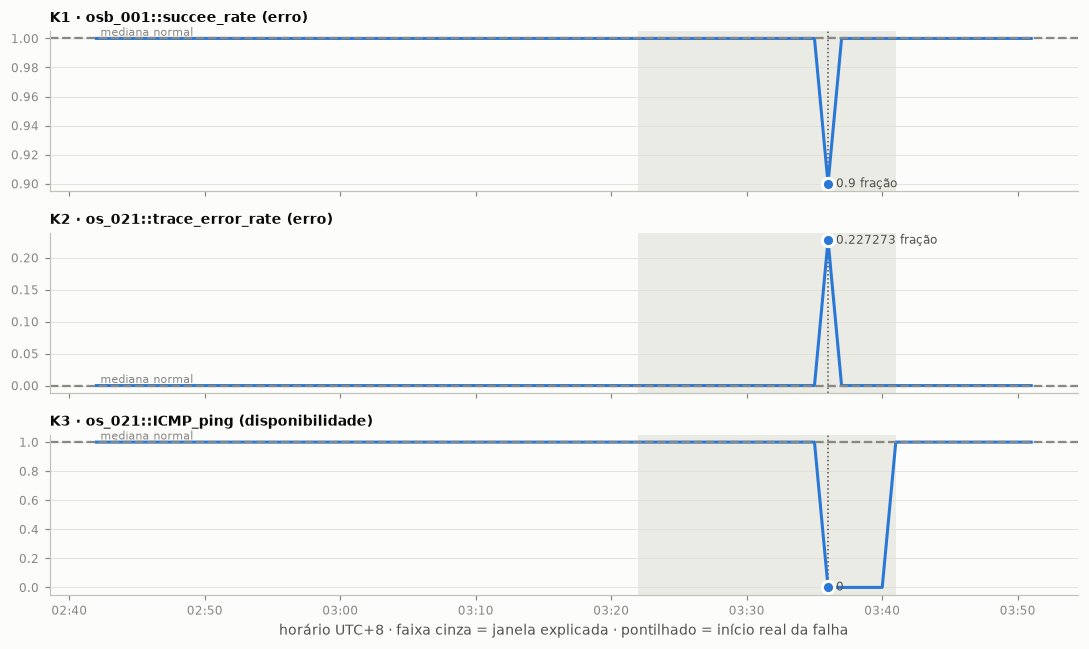

SHAP recalculado igual ao do pacote: True


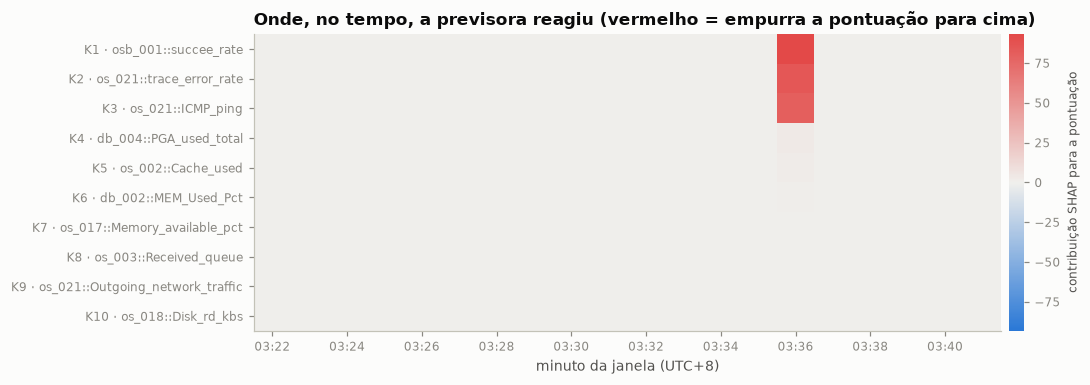

In [15]:
describe(example_b)
plot_series(example_b)
plot_shap(example_b)

**Leitura do exemplo B.** O gabarito é um atraso de rede (`network delay`) no `os_021`, iniciado às 03:36. A janela escolhida pelo detector (03:22–03:41) contém esse início.

- **O que o pacote aponta:**
  - o `os_021` em C1, também em N1 no ranqueamento nativo;
  - dois sintomas no mesmo minuto: a taxa de erro de traces do `os_021` (K2) e a queda de sucesso do serviço `osb_001` (K1), que depende dele.
- **Duas ressalvas:**
  - o K3 é o `ICMP_ping`, um KPI de disponibilidade mantido pela isenção (ameaça nº 1);
  - a categoria sugerida ("erro") não corresponde ao motivo (rede/latência), como a seção 6 antecipou (ameaça nº 13).

  Um agente que leia K1–K3 tem elementos para chegar a "problema de rede no os_021"; um que copie a categoria sugerida, não.

**Atribuição não é causalidade.** O mapa mostra **a que o modelo reagiu**, não o que causou a falha (ameaça nº 14). Um KPI de um componente vizinho, afetado pela falha, pode receber mais atribuição que a causa raiz. Por isso a localização via XAI foi medida contra o gabarito (seção 2), e não presumida. A descoberta causal (Ikram et al., 2022) fica como abordagem complementar na monografia.

## 8. Conclusões da E6

1. **RQ2, localização:**
   - a XAI da previsora supera as heurísticas de z-score nos dois sistemas;
   - no Telecom, empata com o ranqueamento nativo; no Bank, supera-o e é a melhor localização do projeto (SHAP, HR@1 0,48);
   - no Telecom, a vantagem depende em boa parte dos KPIs de disponibilidade.
2. **Fidelidade:** SHAP e LIME apontam atributos que movem a saída (deleção muito melhor que a aleatória). A inserção não serve para a classificadora do Bank, porque a referência normal não é neutra para ela.
3. **Estabilidade:** só a previsora tem explicações reprodutíveis entre seeds e coerentes entre métodos. A classificadora mostra o efeito Rashomon.
4. **Categoria de motivo:** a soma de atribuições por categoria supera o prior de treino só no Bank (SHAP da previsora), não no Telecom. O motivo fica a cargo do raciocínio do agente sobre os KPIs.
5. **Para a E7:** os pacotes têm janela e alarme escolhidos pela classificadora; componentes, KPIs e ranqueamento nativo vêm da previsora, com valor bruto, mediana normal e instante de pico em cada evidência. Nenhum campo de rótulo, e o esquema rejeita campos extras.